In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression

sns.set_style("whitegrid")

# Load original dataset
df = pd.read_csv("../dataset/StudentPerformanceFactors.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
# Input features
X = df.drop(columns=["Exam_Score"])

# Target variable
y = df["Exam_Score"]

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (6607, 19)
Target variable: (6607,)


Numerical feature correlation:
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


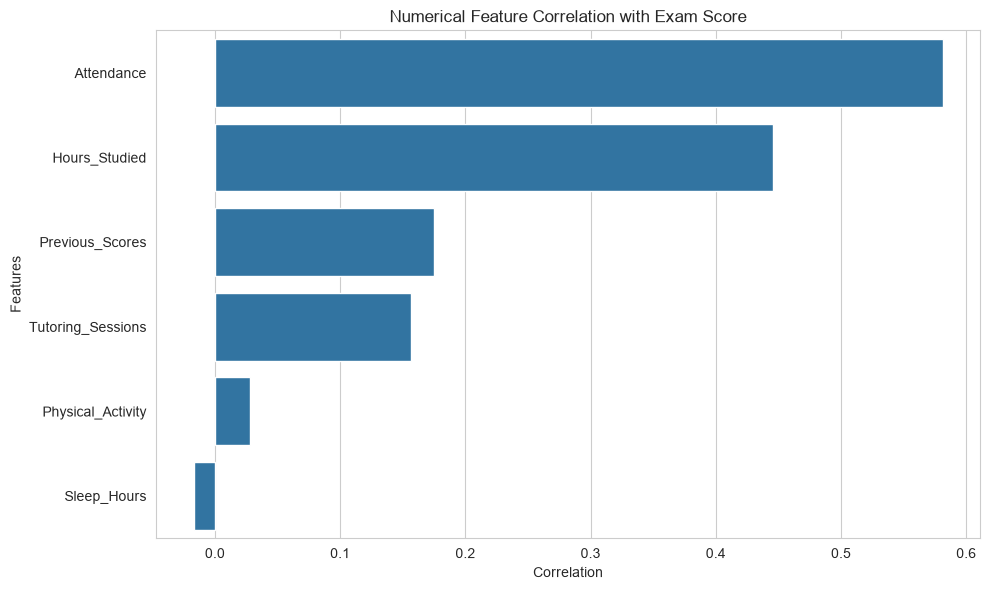

In [3]:
# Correlation with Exam_Score

numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

correlation = (
    df[numerical_columns]
    .corr()["Exam_Score"]
    .drop("Exam_Score")
    .sort_values(ascending=False)
)

print("Numerical feature correlation:")
print(correlation)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlation.values,
    y=correlation.index
)

plt.title("Numerical Feature Correlation with Exam Score")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create a working copy for feature analysis

X_mi = X_train.copy()

# Identify feature types

numerical_columns = X_mi.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_mi.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Impute numerical values

num_imputer = SimpleImputer(strategy="median")

X_mi[numerical_columns] = num_imputer.fit_transform(
    X_mi[numerical_columns]
)

# Impute categorical values

cat_imputer = SimpleImputer(strategy="most_frequent")

X_mi[categorical_columns] = cat_imputer.fit_transform(
    X_mi[categorical_columns]
)

# Encode categorical values

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_mi[categorical_columns] = encoder.fit_transform(
    X_mi[categorical_columns]
)

# Calculate mutual information

mi_scores = mutual_info_regression(
    X_mi,
    y_train,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X_mi.columns,
    "MI_Score": mi_scores
}).sort_values(
    by="MI_Score",
    ascending=False
)

display(mi_results)

,Feature,MI_Score
1,Attendance,0.318968
0,Hours_Studied,0.171761
3,Access_to_Resources,0.033008
6,Previous_Scores,0.020749
2,Parental_Involvement,0.013490
4,Extracurricular_Activities,0.012089
16,Parental_Education_Level,0.011855
9,Tutoring_Sessions,0.010540
14,Physical_Activity,0.009414
18,Gender,0.008945


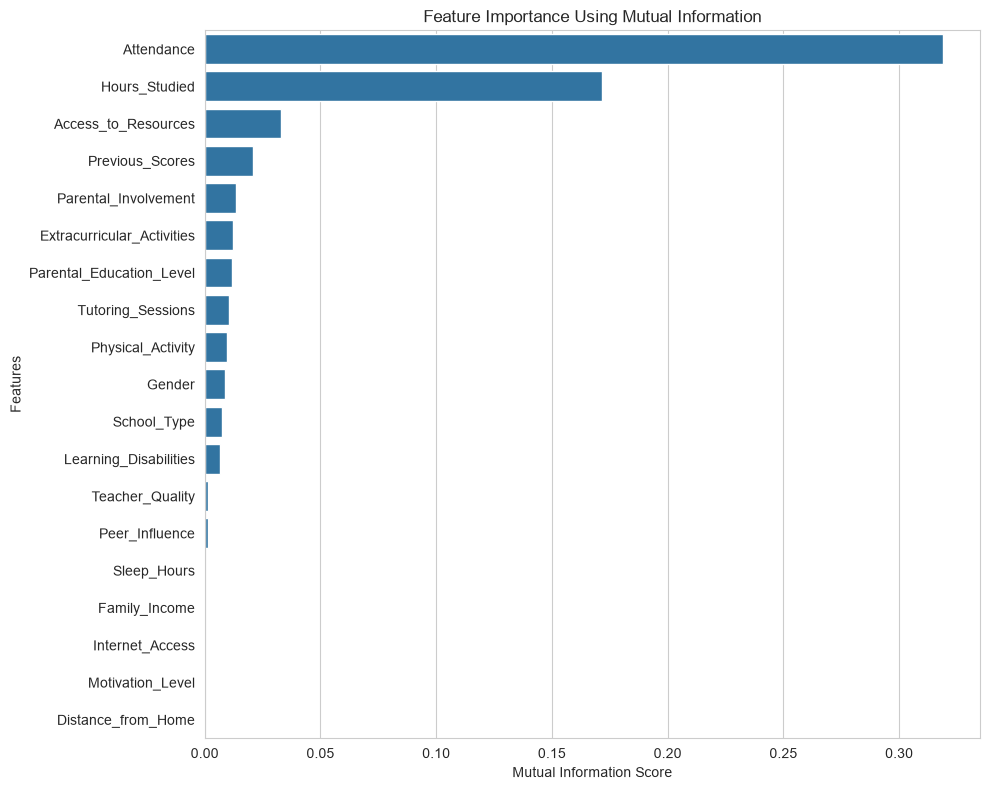

In [5]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=mi_results,
    x="MI_Score",
    y="Feature"
)

plt.title("Feature Importance Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

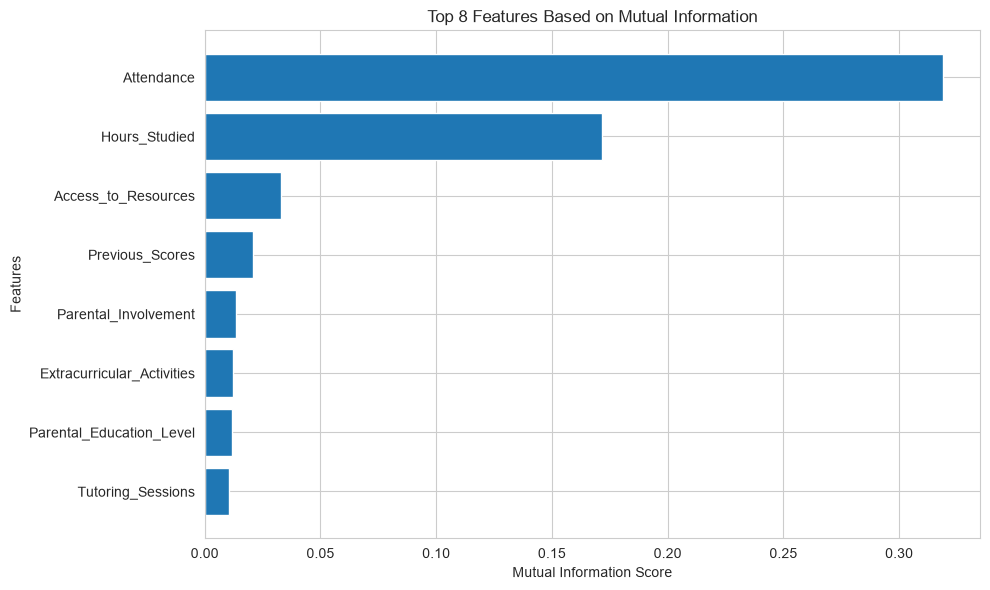

In [6]:
# Select top 8 features

top_features = mi_results.head(8).sort_values(
    by="MI_Score",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["MI_Score"]
)

plt.title("Top 8 Features Based on Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

In [9]:
# Separate features and target

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Identify feature types

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:", numerical_columns)
print("Categorical features:", categorical_columns)

Numerical features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [10]:
# Numerical preprocessing

numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [11]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [12]:
# Extract model and preprocessing objects

model = rf_pipeline.named_steps["model"]
preprocessor = rf_pipeline.named_steps["preprocessor"]

# Get feature importance

importances = model.feature_importances_

# Get original feature names

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Importance": importances
})

# Map each transformed feature to its original column

original_names = []

for transformer_name, transformer, columns in preprocessor.transformers_:

    if transformer_name == "remainder":
        continue

    if transformer_name == "num":
        original_names.extend(columns)

    elif transformer_name == "cat":
        encoder = transformer.named_steps["encoder"]

        for column, categories in zip(
            columns,
            encoder.categories_
        ):
            original_names.extend([column] * len(categories))

importance_df["Original_Feature"] = original_names

# Aggregate importance by original feature

final_importance = (
    importance_df.groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(final_importance)

,Original_Feature,Importance
0,Attendance,0.375375
1,Hours_Studied,0.239336
2,Previous_Scores,0.083233
3,Parental_Involvement,0.035756
4,Access_to_Resources,0.033824
5,Tutoring_Sessions,0.032399
6,Physical_Activity,0.024904
7,Sleep_Hours,0.024841
8,Family_Income,0.020437
9,Parental_Education_Level,0.020274


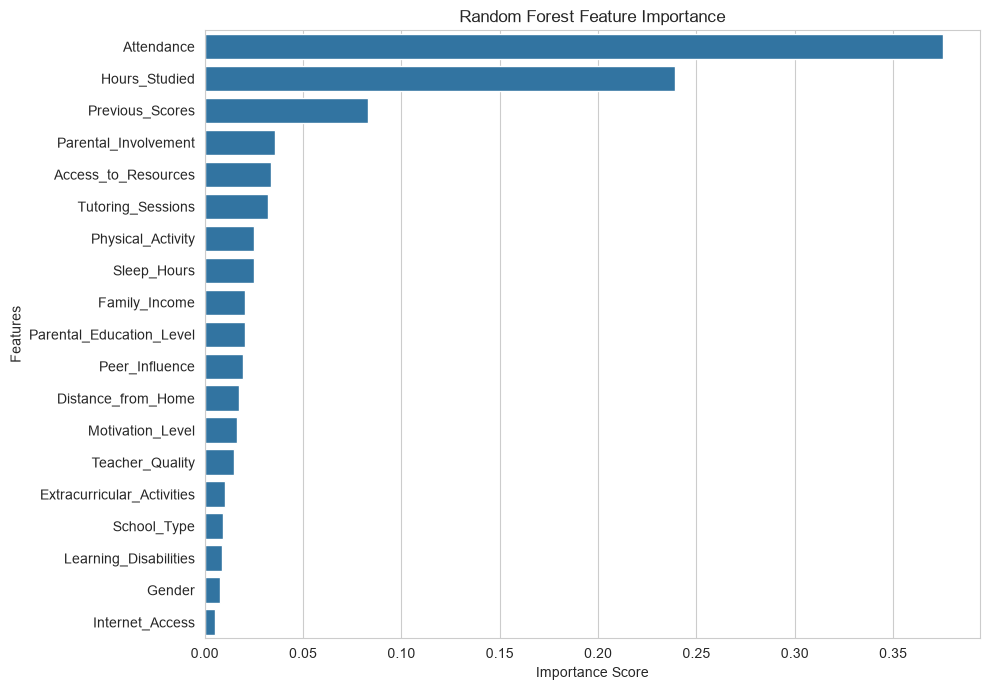

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.barplot(
    data=final_importance,
    x="Importance",
    y="Original_Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [14]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on test data

permutation_result = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Create importance dataframe

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
})

# Sort by importance

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

display(permutation_df)

,Feature,Importance,Std
1,Attendance,1.840248,0.036151
0,Hours_Studied,1.214567,0.033785
6,Previous_Scores,0.248240,0.011543
3,Access_to_Resources,0.200013,0.008653
2,Parental_Involvement,0.160607,0.006359
9,Tutoring_Sessions,0.119723,0.007496
16,Parental_Education_Level,0.045458,0.007383
7,Motivation_Level,0.034578,0.003806
10,Family_Income,0.033741,0.005024
13,Peer_Influence,0.028882,0.002013


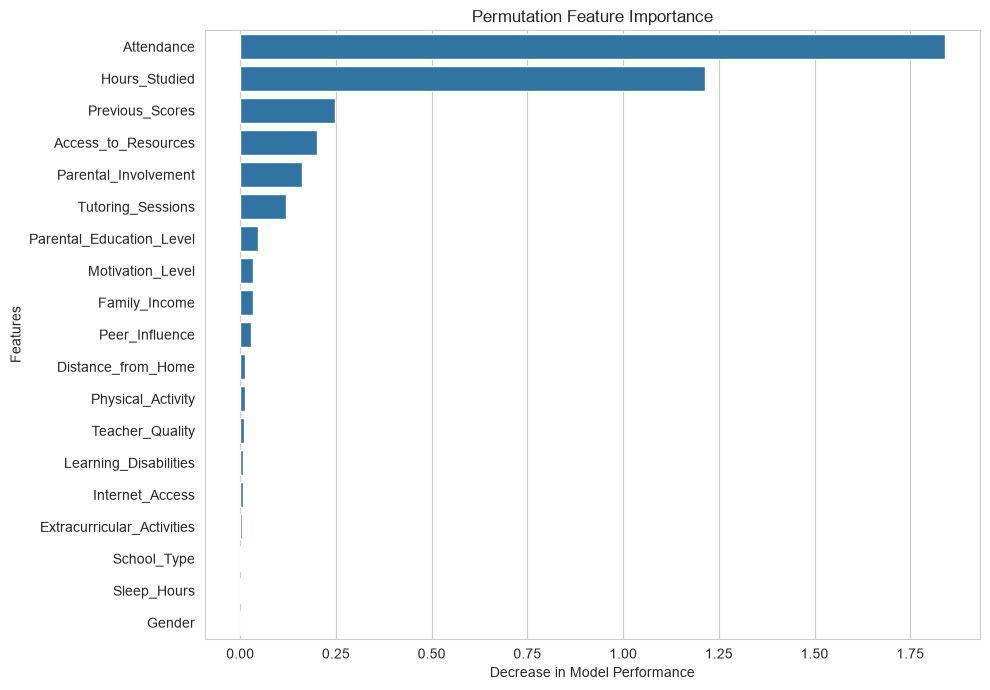

In [15]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=permutation_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Model Performance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [16]:
# Combine feature importance results

feature_comparison = (
    mi_results[["Feature", "MI_Score"]]
    .merge(
        final_importance,
        left_on="Feature",
        right_on="Original_Feature"
    )
    .drop(columns=["Original_Feature"])
    .merge(
        permutation_df[["Feature", "Importance"]],
        on="Feature",
        suffixes=("_RF", "_Permutation")
    )
)

feature_comparison = feature_comparison.rename(
    columns={
        "Importance_RF": "Random_Forest_Importance",
        "Importance_Permutation": "Permutation_Importance"
    }
)

display(feature_comparison)

feature_comparison.to_csv(
    "../dataset/feature_importance_comparison.csv",
    index=False
)

print("Feature importance comparison saved!")

,Feature,MI_Score,Random_Forest_Importance,Permutation_Importance
0,Attendance,0.318968,0.375375,1.840248
1,Hours_Studied,0.171761,0.239336,1.214567
2,Access_to_Resources,0.033008,0.033824,0.200013
3,Previous_Scores,0.020749,0.083233,0.248240
4,Parental_Involvement,0.013490,0.035756,0.160607
5,Extracurricular_Activities,0.012089,0.010415,0.005749
6,Parental_Education_Level,0.011855,0.020274,0.045458
7,Tutoring_Sessions,0.010540,0.032399,0.119723
8,Physical_Activity,0.009414,0.024904,0.011261
9,Gender,0.008945,0.007758,-0.000716


Feature importance comparison saved!
